In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from ucimlrepo import fetch_ucirepo

In [ ]:
dataset = fetch_ucirepo(id=697)
features = dataset.data.features
target = dataset.data.targets["Target"].squeeze()

categorical_features = [
    "Marital Status", "Application mode", "Course", "Daytime/evening attendance",
    "Previous qualification", "Nacionality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    "Displaced", "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International",
]
numeric_features = [name for name in features.columns if name not in categorical_features]

print(f"Dataset UCI 697: {features.shape[0]} filas x {features.shape[1]} predictores")
print(f"Objetivo: {target.name}; clases: {target.nunique()}")

{'uci_id': 697, 'name': "Predict Students' Dropout and Academic Success", 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success', 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv', 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong imbalance towards one of the classes.", 'area': 'Social Sc

# 1. Análisis Exploratorio y de Dimensionalidad

Dataset UCI 697. En esta sección se revisan dimensiones, tipos, cardinalidad, valores faltantes, duplicados y distribución de clases. Las variables categóricas están almacenadas como números, pero sus códigos no representan necesariamente magnitudes.

In [ ]:
eda_summary = pd.DataFrame(
    {
        "valor": [
            features.shape[0],
            features.shape[1],
            len(categorical_features),
            len(numeric_features),
            int(features.isna().sum().sum()),
            int(features.duplicated().sum()),
        ]
    },
    index=[
        "Filas",
        "Predictores",
        "Categóricas nominales",
        "Cuantitativas",
        "Valores faltantes",
        "Filas duplicadas",
    ],
)
display(eda_summary)

(4424, 36)

In [ ]:
display(features.dtypes.value_counts().rename("cantidad de columnas").to_frame())
display(features.nunique().sort_values(ascending=False).rename("valores únicos").to_frame())

In [ ]:
categorical_cardinality = features[categorical_features].nunique().sort_values(ascending=False)
print("Cardinalidad de las variables nominales (códigos tratados como categorías):")
display(categorical_cardinality.to_frame("categorías"))

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [ ]:
display(features[numeric_features].describe().T)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [ ]:
target_counts = target.value_counts().sort_index()
target_share = target.value_counts(normalize=True).sort_index()
display(pd.DataFrame({"estudiantes": target_counts, "proporción": target_share}))

Marital Status                                      6
Application mode                                   18
Application order                                   8
Course                                             17
Daytime/evening attendance                          2
Previous qualification                             17
Previous qualification (grade)                    101
Nacionality                                        21
Mother's qualification                             29
Father's qualification                             34
Mother's occupation                                32
Father's occupation                                46
Admission grade                                   620
Displaced                                           2
Educational special needs                           2
Debtor                                              2
Tuition fees up to date                             2
Gender                                              2
Scholarship holder          

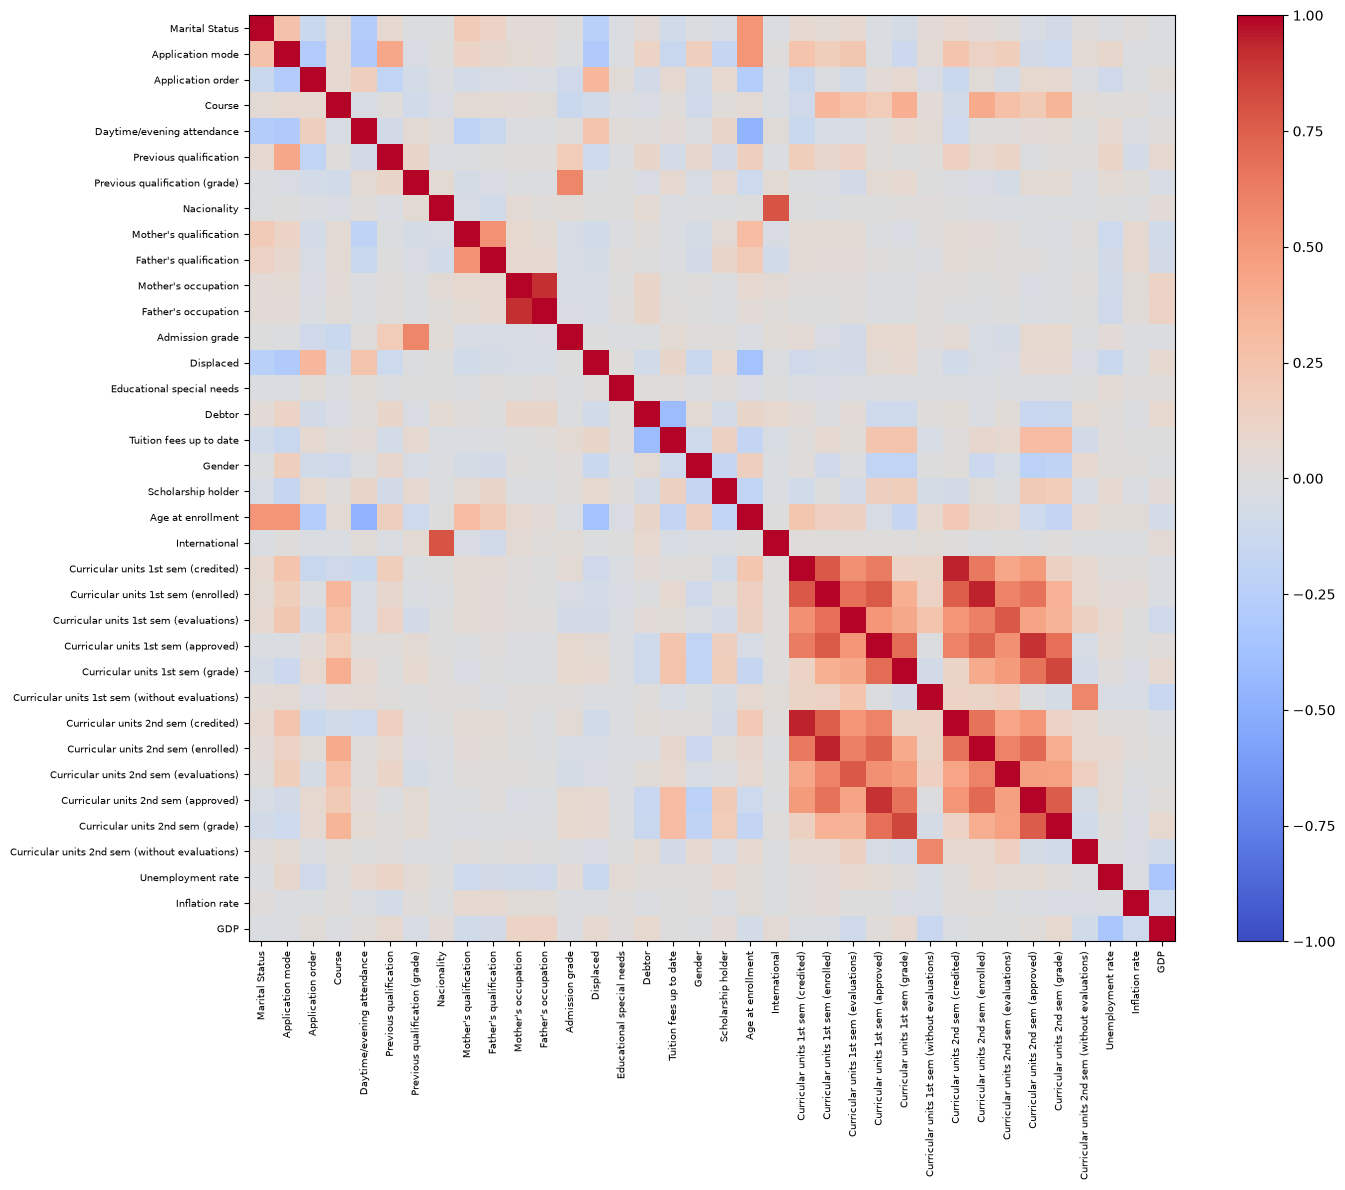

In [ ]:
correlation = features[numeric_features].corr()
figure, axis = plt.subplots(figsize=(14, 11))
image = axis.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=90, fontsize=7)
axis.set_yticks(range(len(correlation.columns)), correlation.columns, fontsize=7)
axis.set_title("Correlación de Pearson entre variables cuantitativas")
figure.colorbar(image, ax=axis, label="Correlación")
figure.tight_layout()
plt.show()

correlated_pairs = []
for first_index, first_name in enumerate(correlation.columns):
    for second_name in correlation.columns[first_index + 1 :]:
        value = correlation.loc[first_name, second_name]
        if pd.notna(value) and abs(value) >= 0.8:
            correlated_pairs.append((first_name, second_name, value))
correlated_pairs = sorted(correlated_pairs, key=lambda row: abs(row[2]), reverse=True)
print("Pares con correlación absoluta >= 0.80:")
print(correlated_pairs if correlated_pairs else "No se encontraron pares sobre el umbral.")
print("Interpretación: la correlación indica asociación lineal, no causalidad. Se excluyeron códigos nominales.")

## 1.1 Variable objetivo y balance de clases

Se reportan conteos y proporciones para contextualizar el desbalance. El pipeline usa `balanced_accuracy` como métrica principal y pesos de clase para que las clases minoritarias cuenten en la evaluación.

In [ ]:
target_counts

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

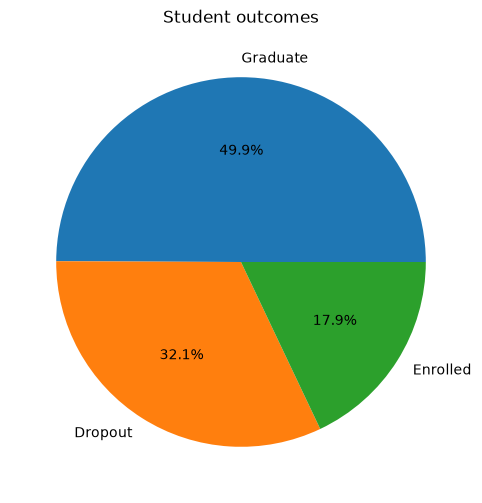

In [ ]:
target_counts.plot.bar(color="#287271", figsize=(7, 4))
plt.ylabel("Estudiantes")
plt.xlabel("Resultado académico")
plt.title("Distribución de clases")
plt.tight_layout()
plt.show()

# 2. Selección de Variables Argumentada

El pipeline obtiene `feature_importances_` del árbol baseline. Las importancias de las columnas one-hot se suman por variable original y se exportan a `artifacts/02_importancia_variables.csv` y `.png`. El ranking justifica relevancia predictiva, no causalidad; se mantienen las variables durante la comparación para evitar filtrar información antes de la validación cruzada. La matriz del punto 1 complementa la discusión mostrando redundancia lineal entre predictores cuantitativos.

# 3. Modelado Dual: Baseline vs. Retador

- **Baseline:** árbol de decisión podado; sus reglas e importancias favorecen interpretabilidad.
- **Retador:** SVM; la búsqueda compara kernel lineal y RBF tras one-hot e imputación de categóricas, e imputación/escalado de variables cuantitativas.
- Ambos clasificadores usan `class_weight="balanced"`; se comparan con balanced accuracy, F1 macro, reporte por clase y matriz de confusión. El ganador se escoge por CV; el test reservado solo estima generalización.

# 4. Ajuste Sistemático de Hiperparámetros

## 4.a GridSearchCV y K-Fold

`GridSearchCV` evalúa todas las combinaciones declaradas. `StratifiedKFold` divide el conjunto de entrenamiento en cinco pliegues preservando la proporción de clases; cada pliegue valida una ronda distinta. Se optimiza balanced accuracy y se informa la desviación entre pliegues. El test separado no interviene en la búsqueda.

El árbol busca `max_depth`, `min_samples_leaf` y `ccp_alpha`. En SVM se prueban `C` y kernels lineal/RBF; `gamma` se ajusta para RBF. Un `C` mayor penaliza más los errores de entrenamiento; RBF permite fronteras no lineales y `gamma` controla el alcance de cada observación.

## 4.b Curvas de Validación y Aprendizaje

`05_curvas_validacion.png` varía `ccp_alpha` en el árbol y `C` en SVM, manteniendo los demás parámetros elegidos por CV. `06_curvas_aprendizaje.png` compara entrenamiento y validación al aumentar la cantidad de datos. Una brecha grande entre ambas curvas sugiere varianza/sobreajuste; puntajes bajos en ambas sugieren sesgo/subajuste. El árbol más podado o el SVM con frontera más simple reduce varianza a costa de posible sesgo; complejidad excesiva hace lo contrario.

Ejecuta `uv run predict-students-dropout-and-academic-success` desde la raíz para generar `artifacts/resultados_taller.md`, métricas, rankings y gráficas. La celda siguiente muestra los resultados guardados después de correr el pipeline.

### Limitación temporal de las variables

El modelo usa resultados del segundo semestre para predecir el estado académico final. Por ello, los resultados no prueban que se pueda alertar sobre deserción al inicio del programa. Para una alerta temprana habría que usar solo información disponible en el momento de intervención y repetir la validación completa.

In [ ]:
artifact_dir = Path("artifacts")
if not artifact_dir.exists() and (Path("..") / "artifacts").exists():
    artifact_dir = Path("..") / "artifacts"

comparison_file = artifact_dir / "03_comparacion_modelos.csv"
importance_file = artifact_dir / "02_importancia_variables.csv"
if comparison_file.exists() and importance_file.exists():
    print("Comparación de modelos (punto 3) y selección por importancia (punto 2):")
    display(pd.read_csv(comparison_file).drop(columns="classification_report_test", errors="ignore"))
    display(pd.read_csv(importance_file).head(15))
    for image_name in [
        "02_importancia_variables.png",
        "05_curvas_validacion.png",
        "06_curvas_aprendizaje.png",
    ]:
        image_path = artifact_dir / image_name
        if image_path.exists():
            display(Image(filename=str(image_path)))
    report_file = artifact_dir / "resultados_taller.md"
    if report_file.exists():
        print(f"Informe detallado: {report_file.resolve()}")
else:
    print("Aún no hay resultados de modelado. Ejecuta el comando descrito en la sección 4 para generarlos.")